<!-- m6:proyecto -->
# Módulo 6 · Proyecto final integrador — Sistema de decisión para PagoYa
**Diplomado en Big Data e Inteligencia Artificial · CEC-EPN** · Ing. Eduardo Avilés · **grupal** · 40 pts del módulo

**Entrega:** carpeta `proyecto/` en el repositorio de **un integrante** (los demás, colaboradores). **Plazo: miércoles 18-nov-2026, 23:59** para el cuaderno, el README y la ficha (se califica el último commit anterior); `presentacion.pdf` hasta el jueves 19-nov, 18:00. **Defensa:** jueves 19-nov, 8 min + 3 min de preguntas.

| Archivo en `proyecto/` | Cómo se crea |
|---|---|
| `proyecto.ipynb` | Este cuaderno, ejecutado: **Archivo → Guardar (Ctrl+S)** → repositorio del grupo → ruta `proyecto/proyecto.ipynb` |
| `README.md` | Informe ejecutivo (1–2 páginas). Ya existe un `proyecto/README.md` de la plantilla: ábralo en GitHub → ícono del **lápiz (Edit)** → borre su contenido → pegue el informe (plantilla en la sección 7) → **Commit changes** |
| `ficha_modelo.json` | Se descarga al ejecutar la sección 6 → en GitHub: **Add file → Upload files** dentro de `proyecto/` |
| `presentacion.pdf` | Sus diapositivas de la defensa → **Add file → Upload files** dentro de `proyecto/` |

### Elija UN problema
| Problema | Datos (`curso.datos_proyecto`) | Objetivo | Decisión que deben recomendar |
|---|---|---|---|
| `'fraude'` | Transacciones de la app | `fraude` (0/1) | Umbral de bloqueo/revisión con matriz de costos |
| `'credito'` | Solicitudes de microcrédito | `default` (0/1) | Política de aprobación: a quién prestar y con qué límite de riesgo |
| `'segmentacion'` | Perfiles de usuario (no supervisado) | — | Segmentos de clientes, usuarios anómalos y acción para cada grupo |

### Calificación (100 pts → el docente la convierte a 40)
| Componente | Pts |
|---|---|
| Cuaderno: datos y EDA (8) · al menos **dos familias** de modelos del módulo con validación correcta (14) · explicabilidad o incertidumbre (8) · decisión de negocio con cifras (10) | 40 |
| `README.md`: informe ejecutivo para un comité | 12 |
| `ficha_modelo.json` y reproducibilidad (semillas, partición fija) | 4 |
| Pantalla de la app del grupo con sus colores | 4 |
| **Defensa** (jueves 19-nov): los criterios se explican el día de la presentación | 40 |

**Reutilice** el código de las clases 1–3 y del deber. Los datos son **propios de cada grupo** (dependen del nombre del grupo).

## 0. Preparación y datos del grupo

In [1]:
import importlib, subprocess, sys
for paquete in ['pymc']:
    if importlib.util.find_spec(paquete) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', paquete])
import os, urllib.request, warnings
URL = 'https://raw.githubusercontent.com/JavyAviles/m6-ia-plantilla/main/curso.py'
if not os.path.exists('curso.py'):
    urllib.request.urlretrieve(URL, 'curso.py')
import curso
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
print('Listo · curso', curso.VERSION)

Listo · curso m6-2026.11


In [2]:
GRUPO = 'Grupo omega'                                   # ✏️ nombre del grupo (el mismo del registro en el aula)
INTEGRANTES = ['Emanuel Yaselga', 'Edwin Cevallos', 'Evelyn Cueva', 'Pablo Segarra']   # ✏️ apellidos y nombres
PROBLEMA = 'segmentacion'                                      # ✏️ 'fraude', 'credito' o 'segmentacion'
NOMBRE_APP, COLOR_PRINCIPAL, COLOR_ALERTA = 'OmegaPay', '#1B4965', '#E63946'   # ✏️ identidad de la app del grupo
SEMILLA = 42
df = curso.datos_proyecto(GRUPO, PROBLEMA)
df.head()

Huella de datos del proyecto: Grupo omega · segmentacion · semilla 416534
Descargados 3006 eventos en 7 páginas de /v1/transacciones
Datos limpios: 2996 transacciones · tasa de fraude 9.55%
Perfiles de usuario: 781


,usuario_id,edad,ingreso_mensual,antiguedad_meses,provincia,n_transacciones,monto_medio,monto_max,pct_noche,pct_dispositivo_nuevo,distancia_media,intentos_medios,fraudes
0,U0000,38.0,1141.57,11,Pichincha,6,107.4117,214.48,0.1667,0.1667,9.7500,1.0000,2
1,U0001,67.0,539.14,18,Loja,7,39.3014,79.50,0.0000,0.0000,8.5429,1.4286,1
2,U0002,66.0,1696.97,40,Loja,4,145.0250,208.23,0.5000,0.2500,11.9750,1.0000,1
3,U0004,30.0,1058.01,47,Manabí,3,101.6833,161.03,0.3333,0.0000,5.4333,1.0000,0
4,U0005,59.0,744.44,8,Guayas,7,59.5871,141.92,0.0000,0.0000,8.5000,1.0000,0


---
## 1. Datos y EDA (8 pts)
Diagnóstico de calidad (`curso.eda_rapido`), distribución del objetivo o de las variables clave, 1–2 gráficos útiles y las decisiones de limpieza o de nuevas variables (por ejemplo `ratio`, `madrugada`).

Filas: 781 · Columnas: 13
IDs duplicados (usuario_id): 0
Valores faltantes: 0 · usuarios duplicados: 0


,count,mean,std,min,25%,50%,75%,max
edad,781.0,44.65,14.96,18.00,32.00,45.00,58.00,70.00
ingreso_mensual,781.0,951.73,478.30,202.13,640.47,844.94,1147.45,4251.42
antiguedad_meses,781.0,30.04,16.87,1.00,16.00,30.00,44.00,60.00
n_transacciones,781.0,3.84,1.90,1.00,2.00,4.00,5.00,11.00
monto_medio,781.0,84.47,62.24,6.61,42.28,70.52,106.14,470.55
monto_max,781.0,159.09,138.02,6.61,70.12,119.54,206.74,988.14
pct_noche,781.0,0.10,0.18,0.00,0.00,0.00,0.20,1.00
pct_dispositivo_nuevo,781.0,0.14,0.20,0.00,0.00,0.00,0.25,1.00
distancia_media,781.0,5.95,3.51,0.00,3.68,5.22,7.70,28.00
intentos_medios,781.0,1.27,0.37,1.00,1.00,1.17,1.50,3.00


Asimetría:
pct_noche                2.39
monto_max                2.31
monto_medio              2.16
intentos_medios          1.87
ingreso_mensual          1.61
pct_dispositivo_nuevo    1.60
distancia_media          1.47
n_transacciones          0.61
antiguedad_meses         0.02
edad                     0.00


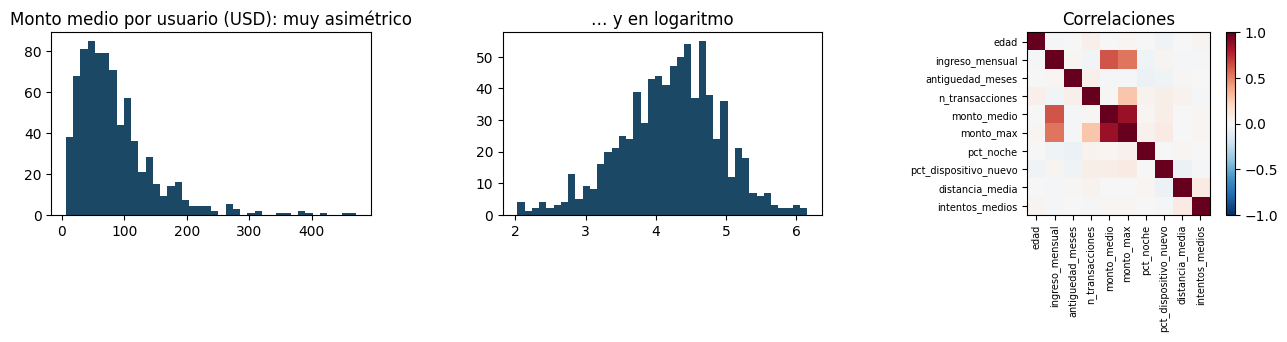

Matriz con todos los usuarios: (781, 10)


In [3]:
from sklearn.preprocessing import StandardScaler
pd.set_option('display.width', 200)
# 1) Diagnóstico de calidad
curso.eda_rapido(df, id_col='usuario_id')
print('Valores faltantes:', int(df.isna().sum().sum()), '· usuarios duplicados:', int(df['usuario_id'].duplicated().sum()))

# 2) Nuevas variables
df['ratio_max'] = df['monto_max'] / df['ingreso_mensual']        # pago más grande frente al ingreso
df['tasa_fraude'] = df['fraudes'] / df['n_transacciones']         # solo para VALIDAR, no entra a los modelos

# 3) Variables para segmentar (perfil + comportamiento); 'fraudes' y 'provincia' quedan fuera
VARS = ['edad', 'ingreso_mensual', 'antiguedad_meses', 'n_transacciones', 'monto_medio', 'monto_max',
        'pct_noche', 'pct_dispositivo_nuevo', 'distancia_media', 'intentos_medios']
display(df[VARS + ['ratio_max', 'fraudes']].describe().T.round(2))
print('Asimetría:'); print(df[VARS].skew().round(2).sort_values(ascending=False).to_string())

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
ax[0].hist(df['monto_medio'], bins=40, color=COLOR_PRINCIPAL); ax[0].set_title('Monto medio por usuario (USD): muy asimétrico')
ax[1].hist(np.log1p(df['monto_medio']), bins=40, color=COLOR_PRINCIPAL); ax[1].set_title('… y en logaritmo')
corr = df[VARS].corr()
im = ax[2].imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1); ax[2].set_title('Correlaciones')
ax[2].set_xticks(range(len(VARS))); ax[2].set_xticklabels(VARS, rotation=90, fontsize=7)
ax[2].set_yticks(range(len(VARS))); ax[2].set_yticklabels(VARS, fontsize=7); plt.colorbar(im, ax=ax[2])
plt.tight_layout(); plt.show()

# 4) Logaritmo a las variables de dinero y distancia, luego escalado (K-Means usa distancias)
LOG = ['ingreso_mensual', 'monto_medio', 'monto_max', 'distancia_media']
X = df[VARS].copy(); X[LOG] = np.log1p(X[LOG])
Z_todos = StandardScaler().fit_transform(X)       # con los 781 usuarios (solo para comparar; el modelo final retira antes las anomalías)
print('Matriz con todos los usuarios:', Z_todos.shape)

**✍️ Hallazgos del EDA:** Son 781 usuarios (perfiles agregados de 2 996 transacciones), sin faltantes ni duplicados. El dinero es muy asimétrico: el monto máximo llega a USD 988 con mediana de USD 120, y el ingreso a USD 4 251 con mediana de USD 845. Por eso apliqué logaritmo a ingreso, montos y distancia antes de escalar; si no, K-Means agruparía solo por dinero. Las correlaciones fuertes son las esperadas (monto medio con monto máximo, 0,86; montos con ingreso, 0,5–0,6); el resto de variables aportan información distinta. Creé `ratio_max` (pago más grande / ingreso) para el detector de anomalías. Como las anomalías se retiran antes de segmentar (Clase 5), la sección 3 tendrá dos pasos: detectar y luego agrupar. `fraudes` y `tasa_fraude` no entran a ningún modelo: las uso solo para **validar** si los segmentos y las anomalías tienen sentido de riesgo.

---
## 2. Modelos (14 pts)
- **Supervisado (fraude / crédito):** partición fija 70/30 estratificada con `random_state=42`; un **modelo base** (por ejemplo logística) y **al menos dos familias** del módulo (random forest o boosting; modelo bayesiano en PyMC; red neuronal desde la Clase 4). Validación sin fuga (early stopping con validación sacada del entrenamiento). Métricas: AUC, exactitud balanceada y Brier.
- **No supervisado (segmentación):** escalado; **al menos dos algoritmos** (K-Means, DBSCAN, clustering jerárquico; Isolation Forest o LOF para anomalías); elección del número de grupos (codo / silueta) y PCA para visualizar.

Isolation Forest marca 39 · LOF marca 39 · coinciden en 27 (3.5%) → se retiran y se tratan aparte; se segmentan 754 usuarios.


,marcados,recall,precisión
Isolation Forest,40.0,1.0,0.38
LOF,40.0,0.0,0.00
Ambos (regla del proyecto),23.0,0.0,0.00
Alguno de los dos,57.0,1.0,0.26


,inercia,silueta_kmeans,silueta_ward,davies_bouldin_kmeans,acuerdo_ARI,tamaño_menor
k,,,,,,
2,6346.457,0.142,0.125,2.222,0.377,341
3,5835.842,0.124,0.086,2.292,0.493,198
4,5495.222,0.108,0.076,2.285,0.449,173
5,5189.966,0.110,0.082,2.075,0.285,115
6,4911.445,0.117,0.082,1.922,0.372,74
7,4673.704,0.113,0.081,1.848,0.248,71
8,4496.173,0.109,0.079,1.853,0.304,57


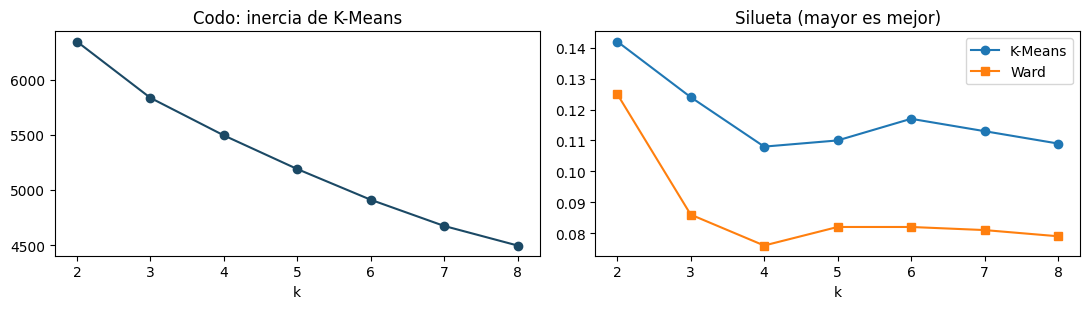

Estabilidad de K-Means con 10 semillas distintas (ARI medio): 0.858


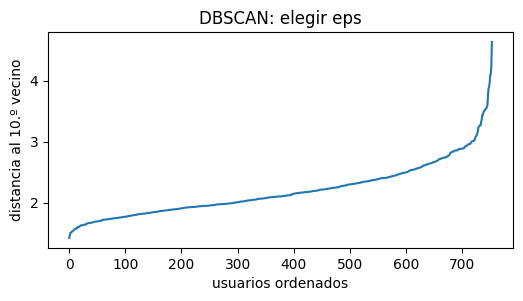

DBSCAN eps=1.5: grupos = 1, ruido = 98%
DBSCAN eps=2.0: grupos = 1, ruido = 27%
DBSCAN eps=2.5: grupos = 1, ruido = 5%


,usuarios,silueta,Davies-Bouldin,estabilidad (ARI 10 semillas),segmento más pequeño,intentos de PIN del segmento más alto
Con anomalías,781,0.108,2.248,0.747,64,2.141
Sin anomalías (elegido),754,0.108,2.285,0.858,173,1.291


ARI entre ambas segmentaciones (mismos 754 usuarios): 0.273
Anómalos que cayeron en cada segmento al incluirlos: [10, 6, 5, 6]
Tasa de fraude del resto de usuarios: 0.083


,K-Means (k=4),Jerárquico Ward (k=4),Isolation Forest (5 %),LOF (5 %)
silueta,0.108,0.076,-,-
Davies-Bouldin,2.285,2.551,-,-
estabilidad (ARI),0.858,-,-,-
tasa de fraude de los marcados,-,-,0.188,0.171


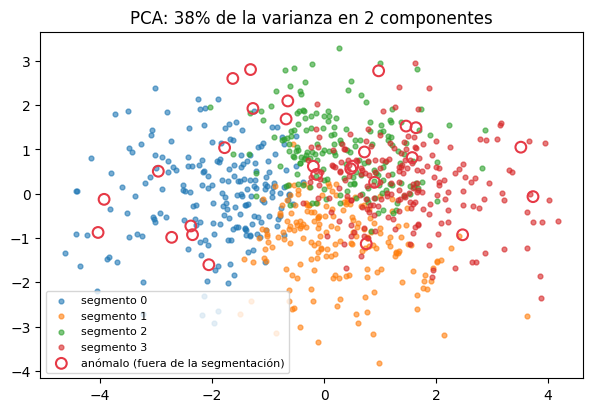

In [4]:
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors

# ═══ A) ANOMALÍAS PRIMERO (Clase 5.3): se detectan y se retiran ANTES de segmentar, porque distorsionan los centroides ═══
RIESGO = ['pct_noche', 'pct_dispositivo_nuevo', 'distancia_media', 'intentos_medios', 'ratio_max']
def marcar(d, contaminacion=0.05):
    """Isolation Forest y LOF sobre las conductas de RIESGO (log y escalado). Devuelve marcas, puntaje y escalador."""
    esc = StandardScaler().fit(np.log1p(d[RIESGO])); Zr = esc.transform(np.log1p(d[RIESGO]))
    iso = IsolationForest(contamination=contaminacion, random_state=SEMILLA).fit(Zr)
    lof = LocalOutlierFactor(n_neighbors=20, contamination=contaminacion).fit_predict(Zr) == -1
    return iso.predict(Zr) == -1, lof, -iso.score_samples(Zr), esc
df['anomalo_iso'], df['anomalo_lof'], df['puntaje_anomalia'], escalador_r = marcar(df)
df['anomalo'] = df['anomalo_iso'] & df['anomalo_lof']              # confirmado por los dos métodos
conservar = ~df['anomalo']
print(f"Isolation Forest marca {df['anomalo_iso'].sum()} · LOF marca {df['anomalo_lof'].sum()} · coinciden en {df['anomalo'].sum()} "
      f"({df['anomalo'].mean():.1%}) → se retiran y se tratan aparte; se segmentan {conservar.sum()} usuarios.")

# Validación del detector con anomalías SEMBRADAS (como en la Clase 5): 15 perfiles anómalos conocidos, solo para evaluar
rng = np.random.default_rng(7); x = df.sample(15, random_state=7).copy()
x['n_transacciones'] = rng.integers(8, 16, 15); x['monto_medio'] = np.round(x['ingreso_mensual'] * rng.uniform(0.45, 0.9, 15), 2)
x['monto_max'] = np.round(x['monto_medio'] * rng.uniform(1.5, 2.5, 15), 2); x['pct_noche'] = np.round(rng.uniform(0.5, 1.0, 15), 4)
x['pct_dispositivo_nuevo'] = np.round(rng.uniform(0.5, 1.0, 15), 4); x['distancia_media'] = np.round(rng.uniform(15, 35, 15), 4)
x['intentos_medios'] = np.round(rng.uniform(2.0, 3.0, 15), 4); x['ratio_max'] = x['monto_max'] / x['ingreso_mensual']
ev = pd.concat([df[RIESGO].assign(sembrada=0), x[RIESGO].assign(sembrada=1)], ignore_index=True)      # copia de evaluación: no toca df
m_iso, m_lof, _, _ = marcar(ev)
val_sembradas = pd.DataFrame({m: {'marcados': int(v.sum()), 'recall': round(float(v[ev['sembrada'] == 1].mean()), 2),
                                  'precisión': round(float(ev['sembrada'][v].mean()), 2)}
                              for m, v in {'Isolation Forest': m_iso, 'LOF': m_lof, 'Ambos (regla del proyecto)': m_iso & m_lof, 'Alguno de los dos': m_iso | m_lof}.items()}).T
display(val_sembradas)

# ═══ B) SEGMENTACIÓN sobre los usuarios sin anomalías (Clase 5.4): logaritmo, escalado y K-Means ═══
LOG = ['ingreso_mensual', 'monto_medio', 'monto_max', 'distancia_media']
X = df.loc[conservar, VARS].copy(); X[LOG] = np.log1p(X[LOG])
escalador = StandardScaler().fit(X); Z = escalador.transform(X)              # Z = solo usuarios sin anomalías

# B1) Número de grupos: codo (inercia) y silueta, comparando K-Means con jerárquico (Ward)
filas = []
for k in range(2, 9):
    km = KMeans(k, n_init=20, random_state=SEMILLA).fit(Z)
    ward = AgglomerativeClustering(k, linkage='ward').fit(Z)
    filas.append({'k': k, 'inercia': km.inertia_, 'silueta_kmeans': silhouette_score(Z, km.labels_),
                  'silueta_ward': silhouette_score(Z, ward.labels_), 'davies_bouldin_kmeans': davies_bouldin_score(Z, km.labels_),
                  'acuerdo_ARI': adjusted_rand_score(km.labels_, ward.labels_), 'tamaño_menor': np.bincount(km.labels_).min()})
eleccion = pd.DataFrame(filas).set_index('k').round(3); display(eleccion)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].plot(eleccion.index, eleccion['inercia'], 'o-', color=COLOR_PRINCIPAL); ax[0].set_title('Codo: inercia de K-Means'); ax[0].set_xlabel('k')
ax[1].plot(eleccion.index, eleccion['silueta_kmeans'], 'o-', label='K-Means'); ax[1].plot(eleccion.index, eleccion['silueta_ward'], 's-', label='Ward')
ax[1].set_title('Silueta (mayor es mejor)'); ax[1].set_xlabel('k'); ax[1].legend(); plt.tight_layout(); plt.show()

# B2) Modelo elegido: K-Means con k = 4 y su estabilidad frente a la semilla
K = 4
kmeans = KMeans(K, n_init=20, random_state=SEMILLA).fit(Z)
df['segmento'] = -1                                                       # -1 = anómalo (fuera de la segmentación)
df.loc[conservar, 'segmento'] = kmeans.labels_
estab = [adjusted_rand_score(kmeans.labels_, KMeans(K, n_init=20, random_state=s).fit(Z).labels_) for s in range(1, 11)]
print(f'Estabilidad de K-Means con 10 semillas distintas (ARI medio): {np.mean(estab):.3f}')

# B3) DBSCAN (densidad) como tercer algoritmo; la distancia al 10.º vecino ayuda a elegir eps
dist = np.sort(NearestNeighbors(n_neighbors=10).fit(Z).kneighbors(Z)[0][:, -1])
plt.figure(figsize=(6, 2.8)); plt.plot(dist); plt.ylabel('distancia al 10.º vecino'); plt.xlabel('usuarios ordenados'); plt.title('DBSCAN: elegir eps'); plt.show()
for eps in [1.5, 2.0, 2.5]:
    lab = DBSCAN(eps=eps, min_samples=10).fit_predict(Z)
    print(f'DBSCAN eps={eps}: grupos = {len(set(lab)) - (-1 in lab)}, ruido = {(lab == -1).mean():.0%}')

# ═══ C) ¿Importa retirar las anomalías? Misma segmentación pero INCLUYÉNDOLAS ═══
Za = Z_todos                                                              # los 781 usuarios, escalados (sección 1)
km_a = KMeans(K, n_init=20, random_state=SEMILLA).fit(Za)
estab_a = np.mean([adjusted_rand_score(km_a.labels_, KMeans(K, n_init=20, random_state=s).fit(Za).labels_) for s in range(1, 11)])
comparacion = pd.DataFrame({
    'usuarios': [len(Za), len(Z)], 'silueta': [silhouette_score(Za, km_a.labels_), silhouette_score(Z, kmeans.labels_)],
    'Davies-Bouldin': [davies_bouldin_score(Za, km_a.labels_), davies_bouldin_score(Z, kmeans.labels_)],
    'estabilidad (ARI 10 semillas)': [estab_a, np.mean(estab)], 'segmento más pequeño': [np.bincount(km_a.labels_).min(), np.bincount(kmeans.labels_).min()],
    'intentos de PIN del segmento más alto': [df.groupby(km_a.labels_)['intentos_medios'].mean().max(), df.loc[conservar].groupby(kmeans.labels_)['intentos_medios'].mean().max()]},
    index=['Con anomalías', 'Sin anomalías (elegido)']).round(3)
display(comparacion)
print(f"ARI entre ambas segmentaciones (mismos {conservar.sum()} usuarios): {adjusted_rand_score(km_a.labels_[conservar.values], kmeans.labels_):.3f}")
print('Anómalos que cayeron en cada segmento al incluirlos:', np.bincount(km_a.labels_[df['anomalo'].values], minlength=K).tolist())

tabla_modelos = pd.DataFrame({
    'K-Means (k=4)': [silhouette_score(Z, kmeans.labels_), davies_bouldin_score(Z, kmeans.labels_), np.mean(estab), '-'],
    'Jerárquico Ward (k=4)': [eleccion.loc[4, 'silueta_ward'], davies_bouldin_score(Z, AgglomerativeClustering(4, linkage='ward').fit(Z).labels_), '-', '-'],
    'Isolation Forest (5 %)': ['-', '-', '-', df.loc[df['anomalo_iso'], 'tasa_fraude'].mean()],
    'LOF (5 %)': ['-', '-', '-', df.loc[df['anomalo_lof'], 'tasa_fraude'].mean()]},
    index=['silueta', 'Davies-Bouldin', 'estabilidad (ARI)', 'tasa de fraude de los marcados'])
print(f"Tasa de fraude del resto de usuarios: {df.loc[~df['anomalo_iso'], 'tasa_fraude'].mean():.3f}")
display(tabla_modelos.map(lambda v: round(v, 3) if isinstance(v, float) else v))

# ═══ D) PCA para visualizar (los anómalos se proyectan con el mismo escalador) ═══
pca = PCA(2, random_state=SEMILLA).fit(Z); P = pca.transform(Z)
Pa = pca.transform(escalador.transform(df.loc[df['anomalo'], VARS].assign(**{c: np.log1p(df.loc[df['anomalo'], c]) for c in LOG})))
fig, ax = plt.subplots(figsize=(7, 4.5))
for s in range(K):
    m = kmeans.labels_ == s; ax.scatter(P[m, 0], P[m, 1], s=12, alpha=0.6, label=f'segmento {s}')
ax.scatter(Pa[:, 0], Pa[:, 1], s=60, facecolors='none', edgecolors=COLOR_ALERTA, lw=1.5, label='anómalo (fuera de la segmentación)')
ax.set_title(f'PCA: {pca.explained_variance_ratio_.sum():.0%} de la varianza en 2 componentes'); ax.legend(fontsize=8); plt.show()

**✍️ Comparación y elección del modelo:**

- **Orden del proceso (Clase 5).** Primero detectamos las anomalías y las retiramos; después segmentamos a los 754 usuarios restantes. Los pocos usuarios extremos arrastran los centroides de K-Means y deforman los segmentos. La sección C lo comprueba con los datos del grupo: **incluyéndolos**, K-Means arma un segmento pequeño (64 usuarios) cuyo rasgo es tener los intentos de PIN más altos (2,1 de promedio), y la estabilidad frente a la semilla es de ARI 0,75. **Sin ellos**, el segmento más pequeño tiene 173 usuarios, los intentos de PIN de todos los segmentos son normales (máximo 1,3), y la estabilidad sube a ARI 0,86. La silueta no cambia (0,108 en ambos casos). Las dos segmentaciones coinciden poco (ARI 0,27 entre los mismos 754 usuarios): el segmento «de errores de PIN» que salía antes era un efecto de los extremos, no un tipo de cliente.
- **Detección de anomalías.** Isolation Forest y LOF, entrenados solo sobre las 5 conductas de riesgo, marcan 39 usuarios cada uno y **coinciden en 27 (3,5 %)**: esos son los anómalos. Como validación externa (el fraude no se usó para entrenar), su tasa de fraude es de 16,7 % frente a 8,6 % del resto. La señal es débil porque son pocos usuarios con pocas operaciones (1,6 en promedio), y el porcentaje de usuarios con *algún* fraude es incluso menor (26 % frente a 31 %).
- **Prueba con anomalías sembradas (como en la Clase 5).** Inyectamos 15 perfiles anómalos conocidos en una **copia** de los datos solo para evaluar los detectores. **Isolation Forest los encuentra todos** (recall 1,0; marca 40 usuarios en total, de los cuales 15 son los sembrados), pero **LOF no encuentra ninguno** (recall 0,0): los 15 forman un grupo compacto y, con `n_neighbors = 20` (más que el tamaño del grupo), LOF los toma por un vecindario normal. La regla «los marcan ambos» es conservadora y funciona con anomalías dispersas, que es lo que muestran los datos reales, pero **no detectaría un grupo organizado de usuarios anómalos**. Si ese fuera el riesgo, conviene usar Isolation Forest solo o «alguno de los dos» (recall 1,0, precisión 0,26).
- **Número de grupos.** La silueta es baja con cualquier k (0,11–0,14) y el codo no tiene un quiebre claro: los usuarios **no forman grupos naturales muy separados**, sino un continuo. La segmentación es una partición útil para actuar, no un descubrimiento de «tipos» puros. Con k = 2 la silueta es mayor (0,142), pero dos grupos no sirven para diseñar acciones. Elegimos **k = 4**: el grupo más pequeño tiene 173 usuarios (no es un residuo) y los cuatro perfiles son interpretables y tienen acciones distintas.
- **K-Means frente a jerárquico (Ward).** Con k = 4, K-Means tiene mejor silueta (0,108 frente a 0,076) y mejor Davies-Bouldin (2,29 frente a 2,55, menor es mejor). Además es estable: con 10 semillas los grupos coinciden en ARI 0,86. Elegimos **K-Means**.
- **DBSCAN** no encuentra grupos de densidad: con eps = 1,5 marca el 98 % como ruido, y con eps = 2,0 o 2,5 deja un solo grupo. Confirma que no hay islas separadas.

---
## 3. Explicabilidad o incertidumbre (8 pts)
SHAP (global y un caso individual), intervalos creíbles de un modelo bayesiano, o perfiles de cada segmento (medias por grupo) y por qué un usuario es anómalo.

segmento,-1,0,1,2,3
usuarios,27.00,197.00,185.00,173.00,199.00
pct_usuarios,0.03,0.25,0.24,0.22,0.25
edad,48.22,41.85,47.56,44.94,43.98
ingreso_mensual,907.51,576.36,1092.21,864.68,1274.40
antiguedad_meses,22.44,31.08,32.02,29.83,28.40
n_transacciones,1.59,3.49,2.63,4.51,5.02
monto_medio,97.22,32.07,98.13,78.32,127.28
monto_max,152.46,51.69,145.21,160.39,278.07
pct_noche,0.44,0.03,0.00,0.30,0.04
pct_dispositivo_nuevo,0.32,0.13,0.01,0.14,0.26


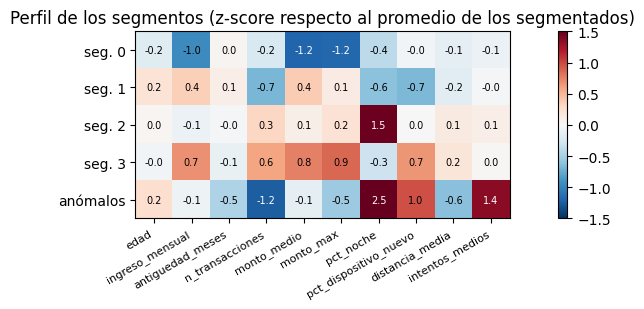

Usuario más anómalo: U0284 · 3 transacciones · fraudes registrados: 3


,valor_usuario,mediana_usuarios,z
pct_dispositivo_nuevo,1.00,0.00,3.58
ratio_max,0.52,0.14,2.91
intentos_medios,2.33,1.17,2.72
distancia_media,7.10,5.22,0.54
pct_noche,0.00,0.00,-0.61


,usuarios,tasa_fraude,con_algun_fraude
anomalo,,,
anómalos,27,0.167,0.259
resto,754,0.086,0.310


In [5]:
# 1) Perfil de cada segmento (medias en unidades originales) y validación con fraude; -1 = anómalos
perfil = df.groupby('segmento').agg(usuarios=('usuario_id', 'size'), **{v: (v, 'mean') for v in VARS}, tasa_fraude=('tasa_fraude', 'mean'))
perfil.insert(1, 'pct_usuarios', perfil['usuarios'] / len(df))
display(perfil.T.round(2))

# 2) Mapa de calor: cuánto se aleja cada segmento de la media (en desviaciones estándar); la última fila son los anómalos
Xa_ = df.loc[df['anomalo'], VARS].copy(); Xa_[LOG] = np.log1p(Xa_[LOG])
zseg = pd.concat([pd.DataFrame(Z, columns=VARS).groupby(kmeans.labels_).mean(),
                  pd.DataFrame(escalador.transform(Xa_), columns=VARS).mean().to_frame('anómalos').T])
fig, ax = plt.subplots(figsize=(10, 3.2))
im = ax.imshow(zseg, cmap='RdBu_r', vmin=-1.5, vmax=1.5)
ax.set_xticks(range(len(VARS))); ax.set_xticklabels(VARS, rotation=30, ha='right', fontsize=8); ax.set_yticks(range(len(zseg)))
ax.set_yticklabels([f'seg. {s}' for s in range(K)] + ['anómalos'])
for i in range(len(zseg)):
    for j in range(len(VARS)): ax.text(j, i, f'{zseg.iloc[i, j]:.1f}', ha='center', va='center', fontsize=7, color='white' if abs(zseg.iloc[i, j]) > 1 else 'black')
ax.set_title('Perfil de los segmentos (z-score respecto al promedio de los segmentados)'); plt.colorbar(im); plt.tight_layout(); plt.show()

# 3) ¿Por qué un usuario es anómalo? El de mayor puntaje entre los confirmados
caso = df[df['anomalo']].sort_values('puntaje_anomalia', ascending=False).iloc[0]
z_caso = pd.Series(escalador_r.transform(np.log1p(caso[RIESGO].astype(float).values.reshape(1, -1)))[0], index=RIESGO)
explicacion = pd.DataFrame({'valor_usuario': caso[RIESGO].astype(float), 'mediana_usuarios': df[RIESGO].median(), 'z': z_caso}).round(2)
print(f"Usuario más anómalo: {caso['usuario_id']} · {int(caso['n_transacciones'])} transacciones · fraudes registrados: {int(caso['fraudes'])}")
display(explicacion.sort_values('z', ascending=False))

# 4) ¿Las anomalías concentran fraude? (validación externa: el fraude no se usó para entrenar)
val = df.groupby(df['anomalo'].map({True: 'anómalos', False: 'resto'})).agg(
    usuarios=('usuario_id', 'size'), tasa_fraude=('tasa_fraude', 'mean'), con_algun_fraude=('fraudes', lambda s: (s > 0).mean()))
display(val.round(3))

**✍️ Interpretación:** El mapa de calor muestra qué define a cada segmento (en desviaciones estándar respecto al promedio):

- **Segmento 0, básicos de bajo monto:** ingreso (−1,0) y pagos (−1,2) bajos; sin conductas de riesgo particulares. Tasa de fraude 4,6 %.
- **Segmento 1, diurnos estables:** casi nunca opera de madrugada (−0,6) ni desde dispositivos nuevos (−0,7), con pocas operaciones (−0,7) y montos medios. Tasa de fraude 4,2 %, la más baja.
- **Segmento 2, nocturnos:** se distingue casi solo por operar de madrugada (+1,5; 30 % de sus pagos). Tasa de fraude 12,5 %.
- **Segmento 3, alto valor multidispositivo:** ingreso (+0,7), pagos (+0,8 y +0,9 en el máximo), más operaciones (+0,6) y más pagos desde dispositivos nuevos (+0,7; 26 %). Tasa de fraude 13,1 %.

La tasa de fraude, que no se usó para formar los grupos, separa dos niveles de riesgo: **4–5 %** en los segmentos 0 y 1 frente a **12–13 %** en los segmentos 2 y 3. La segmentación captura riesgo aunque no lo busque.

**Los anómalos** (última fila del mapa) combinan operar de madrugada (+2,5), intentos de PIN altos (+1,4), más dispositivos nuevos (+1,0) y muy pocas operaciones (−1,2): son cuentas con poca historia y conducta de riesgo.

**Por qué el usuario U0284 es anómalo:** el 100 % de sus pagos los hizo desde un dispositivo nuevo (la mediana es 0 %; z = 3,6), su pago más grande equivale al 52 % de su ingreso (mediana 14 %; z = 2,9) y promedia 2,3 intentos de PIN (mediana 1,2; z = 2,7). Tres señales de riesgo a la vez. Sus 3 operaciones están registradas como fraude.

**Validación:** los anómalos tienen una tasa de fraude de 16,7 % frente a 8,6 % del resto. Son 27 usuarios con pocas operaciones, así que es una señal orientativa, no una prueba de fraude: **«anómalo» no es lo mismo que «fraudulento»**, por eso van a revisión humana y no a bloqueo.

---
## 4. Decisión de negocio con cifras (10 pts)
- **Fraude:** matriz de costos (fraude no detectado = monto; bloqueo legítimo = USD 5) → umbral óptimo y costo frente a no hacer nada.
- **Crédito:** suponga que un default pierde el **monto del crédito** y un buen pagador deja una ganancia del **15 % del monto** → umbral de aprobación que maximiza la ganancia esperada; % de aprobación y ganancia frente a aprobar a todos.
- **Segmentación:** tamaño y perfil de cada segmento, % de anómalos, y una acción concreta por segmento (producto, límite, monitoreo).

In [6]:
# Tamaño, perfil resumido y acción para cada segmento; -1 = anómalos (cola de revisión humana, no bloqueo automático)
NOMBRES = {0: 'Básicos de bajo monto', 1: 'Diurnos estables', 2: 'Nocturnos', 3: 'Alto valor multidispositivo', -1: 'Anómalos'}
ACCIONES = {0: 'Fricción mínima; productos de entrada (microahorro, cashback) con límites estándar', 1: 'Controles estándar y límites medios; ofrecer productos de ahorro e inversión; es el grupo de menor riesgo', 2: 'Alertas en tiempo real de operaciones de madrugada, límite a montos nocturnos y educación antifraude', 3: 'Verificación de identidad (biometría) al cambiar de dispositivo, límites altos con confirmación si el pago supera 40 % del ingreso',
            -1: 'Revisión manual semanal del perfil y límites temporales hasta verificar identidad; no se bloquean automáticamente'}
df['nombre_segmento'] = df['segmento'].map(NOMBRES)
resumen = perfil[['usuarios', 'pct_usuarios', 'ingreso_mensual', 'monto_medio', 'n_transacciones', 'pct_noche',
                  'pct_dispositivo_nuevo', 'intentos_medios', 'tasa_fraude']].copy()
resumen.insert(0, 'nombre', pd.Series(NOMBRES)); resumen['accion'] = pd.Series(ACCIONES)
resumen['fraudes_totales'] = df.groupby('segmento')['fraudes'].sum()
resumen['pct_de_todos_los_fraudes'] = resumen['fraudes_totales'] / df['fraudes'].sum()
display(resumen.round(3))
print(f"Anómalos: {df['anomalo'].sum()} usuarios ({df['anomalo'].mean():.1%}) concentran {df.loc[df['anomalo'], 'fraudes'].sum()} de {df['fraudes'].sum()} fraudes "
      f"({df.loc[df['anomalo'], 'fraudes'].sum() / df['fraudes'].sum():.1%})")
print(f"Tasa media de fraude: anómalos {df.loc[df['anomalo'], 'tasa_fraude'].mean():.1%} · resto {df.loc[~df['anomalo'], 'tasa_fraude'].mean():.1%}")

,nombre,usuarios,pct_usuarios,ingreso_mensual,monto_medio,n_transacciones,pct_noche,pct_dispositivo_nuevo,intentos_medios,tasa_fraude,accion,fraudes_totales,pct_de_todos_los_fraudes
segmento,,,,,,,,,,,,,
-1,Anómalos,27,0.035,907.506,97.222,1.593,0.444,0.318,1.707,0.167,Revisión manual semanal del perfil y límites t...,9,0.031
0,Básicos de bajo monto,197,0.252,576.363,32.068,3.492,0.032,0.129,1.231,0.046,Fricción mínima; productos de entrada (microah...,39,0.136
1,Diurnos estables,185,0.237,1092.210,98.129,2.632,0.000,0.011,1.250,0.042,Controles estándar y límites medios; ofrecer p...,21,0.073
2,Nocturnos,173,0.222,864.680,78.320,4.509,0.300,0.139,1.291,0.125,Alertas en tiempo real de operaciones de madru...,97,0.339
3,Alto valor multidispositivo,199,0.255,1274.401,127.280,5.015,0.045,0.261,1.265,0.131,Verificación de identidad (biometría) al cambi...,120,0.420


Anómalos: 27 usuarios (3.5%) concentran 9 de 286 fraudes (3.1%)
Tasa media de fraude: anómalos 16.7% · resto 8.6%


**✍️ Recomendación:**

| Segmento | Usuarios | Perfil | Tasa de fraude | % de los fraudes | Acción |
|---|---|---|---|---|---|
| 0 · Básicos de bajo monto | 197 (25 %) | Ingreso USD 576, pagos de USD 32 | 4,6 % | 14 % | Fricción mínima; productos de entrada (microahorro, cashback) con límites estándar |
| 1 · Diurnos estables | 185 (24 %) | Ingreso USD 1 092, pagos de USD 98, nunca de madrugada ni dispositivos nuevos | 4,2 % | 7 % | Controles estándar, límites medios y productos de ahorro e inversión; es el grupo de menor riesgo |
| 2 · Nocturnos | 173 (22 %) | 4,5 operaciones, 30 % de madrugada | 12,5 % | 34 % | Alertas en tiempo real de operaciones de madrugada, límite a montos nocturnos y educación antifraude |
| 3 · Alto valor multidispositivo | 199 (25 %) | Ingreso USD 1 274, pagos de USD 127 (máximo USD 278), 5 operaciones, 26 % desde dispositivo nuevo | 13,1 % | 42 % | Verificación de identidad (biometría) al cambiar de dispositivo; límites altos con confirmación si el pago supera 40 % del ingreso |
| Anómalos | 27 (3 %) | Poca historia (1,6 operaciones), 44 % de madrugada, intentos de PIN altos | 16,7 % | 3 % | Cola de revisión manual semanal y límites temporales hasta verificar identidad; **sin bloqueo automático** |

**Prioridad:** los segmentos **Alto valor multidispositivo** y **Nocturnos** juntos son el 47 % de los usuarios y concentran el **76 % de los fraudes**: ahí rinde más el monitoreo. Los segmentos **Básicos** y **Diurnos estables** (49 % de los usuarios, 21 % de los fraudes) pueden operar con menos fricción, lo que mejora la experiencia de casi la mitad de la base.

**Cómo se usaría:** al registrarse o recalcularse cada trimestre, el usuario se asigna a un segmento (K-Means ya ajustado) o, si lo marcan Isolation Forest y LOF, entra a la cola de revisión. Cada segmento activa su política. La decisión final sobre un anómalo la toma una persona.

---
## 5. Pantalla de la app del grupo (4 pts)
Muestre un caso real de sus datos con `curso.pantalla_resultado(...)` (o una pantalla propia). Ejemplo: `curso.pantalla_resultado(NOMBRE_APP, COLOR_PRINCIPAL, COLOR_ALERTA, 'Solicitud CR-00012', ['Ingreso: USD 850', 'Monto: USD 1 200'], probs=probs)`

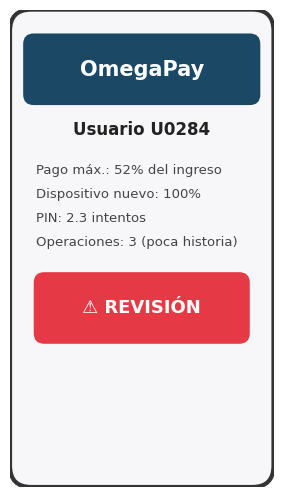

In [7]:
u = df[df['anomalo']].sort_values('puntaje_anomalia', ascending=False).iloc[0]
curso.pantalla_resultado(NOMBRE_APP, COLOR_PRINCIPAL, COLOR_ALERTA, f"Usuario {u['usuario_id']}",
                         [f"Pago máx.: {u['ratio_max']:.0%} del ingreso",
                          f"Dispositivo nuevo: {u['pct_dispositivo_nuevo']:.0%}",
                          f"PIN: {u['intentos_medios']:.1f} intentos",
                          f"Operaciones: {int(u['n_transacciones'])} (poca historia)"],
                         etiqueta='⚠️ REVISIÓN')

---
## 6. Ficha del modelo (4 pts)
Ejecute y suba el archivo descargado a `proyecto/` en GitHub (**Add file → Upload files**).

In [8]:
ficha = curso.ficha_modelo(GRUPO, PROBLEMA,
                           modelo='Isolation Forest + LOF (5 %) para anomalías, retiradas antes de segmentar con K-Means (k=4)',
                           metricas={'silueta_kmeans': round(float(silhouette_score(Z, kmeans.labels_)), 4),
                                     'davies_bouldin': round(float(davies_bouldin_score(Z, kmeans.labels_)), 4),
                                     'estabilidad_ari': round(float(np.mean(estab)), 4),
                                     'estabilidad_ari_con_anomalias': round(float(estab_a), 4),
                                     'usuarios_segmentados': int(conservar.sum()),
                                     'pct_anomalos': round(float(df['anomalo'].mean()), 4),
                                     'recall_sembradas_if': float(val_sembradas.loc['Isolation Forest', 'recall']),
                                     'recall_sembradas_lof': float(val_sembradas.loc['LOF', 'recall']),
                                     'recall_sembradas_ambos': float(val_sembradas.loc['Ambos (regla del proyecto)', 'recall']),
                                     'tasa_fraude_anomalos': round(float(df.loc[df['anomalo'], 'tasa_fraude'].mean()), 4),
                                     'tasa_fraude_resto': round(float(df.loc[~df['anomalo'], 'tasa_fraude'].mean()), 4)},
                           hiperparametros={'orden': 'anomalías primero, luego segmentación sin ellas',
                                            'kmeans': {'n_clusters': K, 'n_init': 20}, 'variables': VARS, 'log': LOG,
                                            'isolation_forest': {'contamination': 0.05}, 'lof': {'n_neighbors': 20, 'contamination': 0.05},
                                            'variables_riesgo': RIESGO})

{
  "grupo": "Grupo omega",
  "problema": "segmentacion",
  "modelo": "Isolation Forest + LOF (5 %) para anomalías, retiradas antes de segmentar con K-Means (k=4)",
  "metricas": {
    "silueta_kmeans": 0.1076,
    "davies_bouldin": 2.285,
    "estabilidad_ari": 0.8583,
    "estabilidad_ari_con_anomalias": 0.7469,
    "usuarios_segmentados": 754,
    "pct_anomalos": 0.0346,
    "recall_sembradas_if": 1.0,
    "recall_sembradas_lof": 0.0,
    "recall_sembradas_ambos": 0.0,
    "tasa_fraude_anomalos": 0.1667,
    "tasa_fraude_resto": 0.0859
  },
  "hiperparametros": {
    "orden": "anomalías primero, luego segmentación sin ellas",
    "kmeans": {
      "n_clusters": 4,
      "n_init": 20
    },
    "variables": [
      "edad",
      "ingreso_mensual",
      "antiguedad_meses",
      "n_transacciones",
      "monto_medio",
      "monto_max",
      "pct_noche",
      "pct_dispositivo_nuevo",
      "distancia_media",
      "intentos_medios"
    ],
    "log": [
      "ingreso_mensual",
     

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## 7. Plantilla del informe (`proyecto/README.md`)
En GitHub abra `proyecto/README.md` → **lápiz (Edit)** → reemplace todo por este texto completado con sus cifras → **Commit changes**:

```
# Sistema de decisión para PagoYa — <Grupo>
Integrantes: ...   ·   Problema: ...

## 1. Problema y datos
## 2. Modelos comparados (tabla de métricas)
## 3. Qué explica el resultado (variables, segmentos, incertidumbre)
## 4. Recomendación con cifras
## 5. Limitaciones y próximos pasos
```